In [84]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/uciml/adult-census-income/adult.csv


In [85]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Chargement du dataset Adult (version Kaggle, 32 561 lignes)
df = pd.read_csv("/kaggle/input/datasets/uciml/adult-census-income/adult.csv")
print(df.shape)          # attendu : (32561, 15)
print(df["income"].unique())   # attendu : ['<=50K' '>50K']

(32561, 15)
['<=50K' '>50K']


In [86]:
# Cible construite UNE SEULE FOIS depuis la colonne d'origine : 1 si >50K, sinon 0
y = (df["income"].astype(str).str.strip() == ">50K").astype(int)
print(y.value_counts())  # doit montrer deux classes : 0 (~24720) et 1 (~7841)

# Variables explicatives : toutes les colonnes sauf la cible
X = df.drop(columns="income").copy()

income
0    24720
1     7841
Name: count, dtype: int64


In [87]:
from sklearn.preprocessing import LabelEncoder

# Chaque colonne texte (workclass, education, sex...) est transformée en nombres.
# Les "?" sont conservés comme une catégorie à part.
for col in X.select_dtypes(include="object").columns:
    X[col] = LabelEncoder().fit_transform(X[col].astype(str))

print(X.dtypes.unique())   # doit n'afficher que des types numériques

[dtype('int64')]


In [88]:
from sklearn.preprocessing import StandardScaler

# Centre et réduit toutes les variables (moyenne 0, écart-type 1), comme IASD21
scaler = StandardScaler()
X = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)
X.head()

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country
0,3.769612,-2.65732,-1.067997,0.181332,-0.420060,2.249480,-1.554283,-0.277805,0.393668,-1.422331,-0.14592,10.593507,-0.035429,0.291569
1,3.183112,0.09005,-0.539169,0.181332,-0.420060,2.249480,-0.608387,-0.277805,0.393668,-1.422331,-0.14592,10.593507,-1.817204,0.291569
2,2.010110,-2.65732,-0.035220,1.214869,-0.031360,2.249480,-1.554283,1.589322,-1.962621,-1.422331,-0.14592,10.593507,-0.035429,0.291569
3,1.130359,0.09005,-0.468215,-1.368974,-2.363558,-1.734058,0.101036,1.589322,0.393668,-1.422331,-0.14592,9.461864,-0.035429,0.291569
4,0.177296,0.09005,0.709482,1.214869,-0.031360,1.585557,0.810458,0.966947,0.393668,-1.422331,-0.14592,9.461864,-0.035429,0.291569


In [89]:
from sklearn.model_selection import train_test_split

# Mêmes paramètres que IASD21 : 80 % train, 20 % test, random_state=42
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

print("Taille de X_train :", X_train.shape)   # attendu : (26048, 14)
print("Taille de X_test  :", X_test.shape)    # attendu : (6513, 14)

Taille de X_train : (26048, 14)
Taille de X_test  : (6513, 14)


Valeurs manquantes : 0
income
0    19744
1     6304
Name: count, dtype: int64
income
0    0.758
1    0.242
Name: proportion, dtype: float64
Baseline test (toujours <=50K) : 0.764


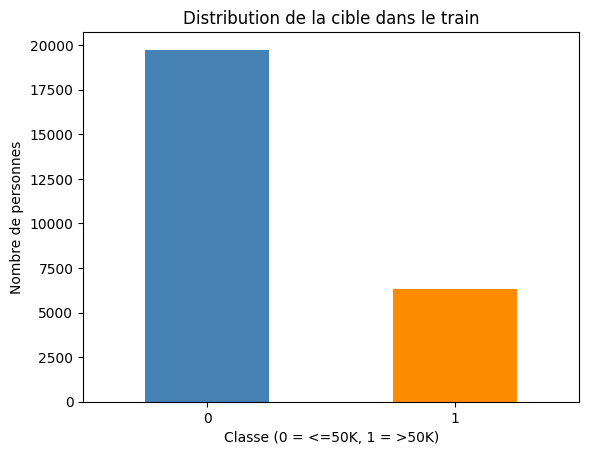

In [90]:
print("Valeurs manquantes :", X_train.isna().sum().sum())   # attendu : 0
print(y_train.value_counts())                                # deux classes obligatoires
print(y_train.value_counts(normalize=True).round(3))
print("Baseline test (toujours <=50K) :", round(1 - y_test.mean(), 3))

# Graphique de la distribution de la cible
y_train.value_counts().sort_index().plot(kind="bar", color=["steelblue", "darkorange"])
plt.title("Distribution de la cible dans le train")
plt.xlabel("Classe (0 = <=50K, 1 = >50K)")
plt.ylabel("Nombre de personnes")
plt.xticks(rotation=0)
plt.show()

In [91]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay, roc_curve)

def evaluer(nom, model, X_te, y_te):
    """Calcule les métriques d'un modèle sur le jeu de test."""
    y_pred = model.predict(X_te)
    y_proba = model.predict_proba(X_te)[:, 1]   # probabilité de la classe >50K
    return {"modele": nom,
            "accuracy": accuracy_score(y_te, y_pred),
            "precision": precision_score(y_te, y_pred),
            "recall": recall_score(y_te, y_pred),
            "f1": f1_score(y_te, y_pred),
            "auc": roc_auc_score(y_te, y_proba)}

In [92]:
from sklearn.naive_bayes import GaussianNB
from sklearn.utils.class_weight import compute_sample_weight
try:
    from imblearn.over_sampling import SMOTE
except ImportError:
    !pip install -q imbalanced-learn
    from imblearn.over_sampling import SMOTE

resultats = []

# 1. Sans correction du déséquilibre
nb = GaussianNB().fit(X_train, y_train)
resultats.append(evaluer("NB sans correction", nb, X_test, y_test))

# 2. Pondération : la classe rare (>50K) pèse plus lourd
w = compute_sample_weight("balanced", y_train)
nb_w = GaussianNB().fit(X_train, y_train, sample_weight=w)
resultats.append(evaluer("NB pondération", nb_w, X_test, y_test))

# 3. Probabilités a priori égales (50 % / 50 %)
nb_p = GaussianNB(priors=[0.5, 0.5]).fit(X_train, y_train)
resultats.append(evaluer("NB priors 50/50", nb_p, X_test, y_test))

# 4. SMOTE : exemples artificiels de >50K, uniquement sur le train
X_sm, y_sm = SMOTE(random_state=42).fit_resample(X_train, y_train)
print("Après SMOTE :", pd.Series(y_sm).value_counts().to_dict())
nb_s = GaussianNB().fit(X_sm, y_sm)
resultats.append(evaluer("NB + SMOTE", nb_s, X_test, y_test))

tableau = pd.DataFrame(resultats).round(4)
tableau

Après SMOTE : {0: 19744, 1: 19744}


,modele,accuracy,precision,recall,f1,auc
0,NB sans correction,0.8016,0.6623,0.3253,0.4363,0.8517
1,NB pondération,0.8142,0.6586,0.4418,0.5288,0.8517
2,NB priors 50/50,0.8142,0.6586,0.4418,0.5288,0.8517
3,NB + SMOTE,0.8190,0.6639,0.4717,0.5515,0.8533


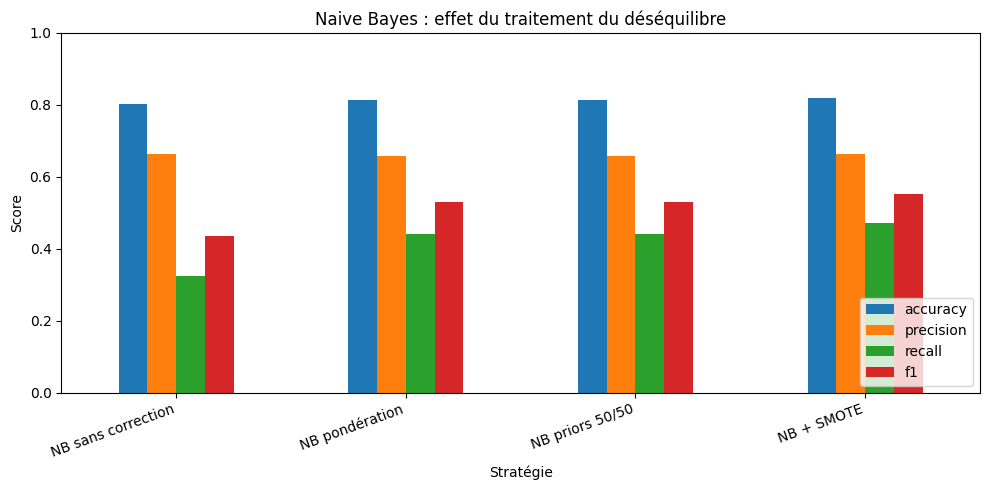

In [93]:
tableau.set_index("modele")[["accuracy", "precision", "recall", "f1"]].plot(
    kind="bar", figsize=(10, 5))
plt.title("Naive Bayes : effet du traitement du déséquilibre")
plt.ylabel("Score")
plt.xlabel("Stratégie")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

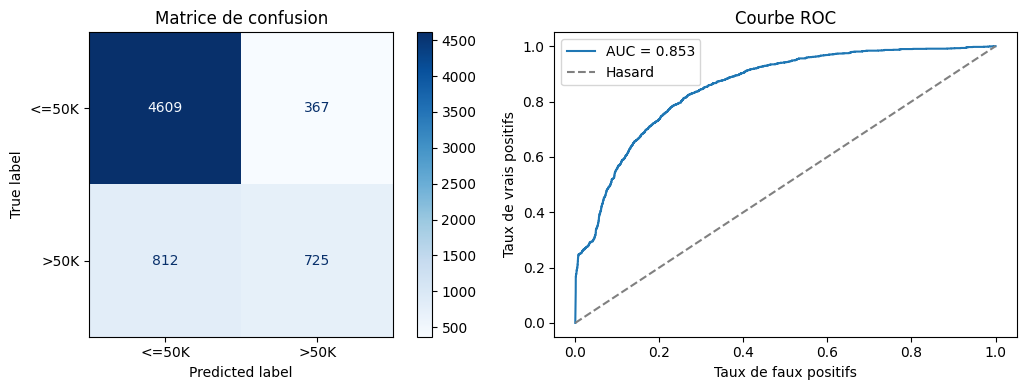

In [94]:
# Choisissez le modèle avec le meilleur F1 du tableau : nb, nb_w, nb_p ou nb_s
modele_final = nb_s

y_pred = modele_final.predict(X_test)
y_proba = modele_final.predict_proba(X_test)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Matrice de confusion
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=["<=50K", ">50K"]).plot(ax=axes[0], cmap="Blues")
axes[0].set_title("Matrice de confusion")

# Courbe ROC
fpr, tpr, _ = roc_curve(y_test, y_proba)
axes[1].plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, y_proba):.3f}")
axes[1].plot([0, 1], [0, 1], "--", color="gray", label="Hasard")
axes[1].set_xlabel("Taux de faux positifs")
axes[1].set_ylabel("Taux de vrais positifs")
axes[1].set_title("Courbe ROC")
axes[1].legend()
plt.tight_layout()
plt.show()

In [95]:
# Effet du seuil de décision sur precision / recall / F1 (modèle NB + SMOTE)
for seuil in [0.3, 0.4, 0.5, 0.6, 0.7]:
    y_pred_s = (y_proba >= seuil).astype(int)
    print(f"Seuil {seuil} | precision {precision_score(y_test, y_pred_s):.3f} "
          f"| recall {recall_score(y_test, y_pred_s):.3f} "
          f"| F1 {f1_score(y_test, y_pred_s):.3f}")

Seuil 0.3 | precision 0.600 | recall 0.627 | F1 0.613
Seuil 0.4 | precision 0.639 | recall 0.534 | F1 0.582
Seuil 0.5 | precision 0.664 | recall 0.472 | F1 0.552
Seuil 0.6 | precision 0.675 | recall 0.420 | F1 0.518
Seuil 0.7 | precision 0.673 | recall 0.370 | F1 0.478


Lecture de la matrice de confusion
	Prédit <=50K	Prédit >50K
Réel <=50K	4 609 (vrais négatifs)	367 (faux positifs)
Réel >50K	812 (faux négatifs)	725 (vrais positifs)

Le total fait 6 513, soit exactement la taille du test. Les chiffres sont cohérents avec votre tableau :

Accuracy = (4 609 + 725) / 6 513 = 0,819
Precision = 725 / (725 + 367) = 0,664
Recall = 725 / (725 + 812) = 0,472
Observations à écrire : matrice de confusion

1. Le modèle reconnaît très bien la classe majoritaire.

Sur les 4 976 personnes à <=50K du test, 4 609 sont correctement classées (environ 93 %). Seulement 367 sont prédites à tort en >50K (faux positifs).

2. Le modèle rate encore plus de la moitié des revenus élevés.

Sur les 1 537 personnes à >50K, seules 725 sont détectées (recall = 0,472). Les 812 autres sont classées à tort en <=50K (faux négatifs). Les faux négatifs (812) sont plus de deux fois plus nombreux que les faux positifs (367) : même après SMOTE, le modèle reste trop prudent et favorise la classe majoritaire.

3. Impact selon l’usage.

Si l’objectif est de ne pas manquer les hauts revenus (par exemple pour un ciblage), les 812 faux négatifs sont le principal défaut. Si l’objectif est d’éviter les fausses alertes, la precision de 0,664 est correcte.

Observations à écrire : courbe ROC

4. La courbe est nettement au-dessus de la diagonale.

L’AUC de 0,853 montre que le modèle sépare bien les deux classes : pour un couple (personne à >50K, personne à <=50K) tiré au hasard, il attribue la probabilité la plus élevée à la bonne personne dans environ 85 % des cas. Un classifieur aléatoire aurait une AUC de 0,5.

5. Le modèle peut atteindre un meilleur recall en changeant le seuil.

La courbe monte vite au début : pour un taux de faux positifs d’environ 20 %, le taux de vrais positifs dépasse 70 %. Le seuil de décision par défaut (0,5) n’est donc pas optimal pour la classe >50K : abaisser le seuil augmenterait le recall au prix d’une baisse de precision.

6. Un décrochage initial.

On observe un petit palier près de l’origine (taux de vrais positifs d’environ 0,25 pour un taux de faux positifs presque nul). Il correspond à des personnes avec un fort capital.gain que le modèle classe avec une grande certitude en >50K.